# MACHINE LEARNING - CA1 | Exploring Diabetes Risk Prediction through Machine Learning: Clinical and Lifestyle Indicators.

Claudia Victoria Vilchis Mondragon

Diabetes is a major public health problem, affecting 589 million adults worldwide (International Diabetes Federation, 2025). This project uses the Diabetes Health Indicators dataset, based on the CDC’s BRFSS 2015 survey (253,680 responses), to compare machine learning classification models for predicting diabetes risk.

Research questions: 
1. What kind of machine-learning model is best at predicting diabetes risk, and why?
2. Which lifestyle factors are most significant in predicting diabetes risk compared with clinical indicators?
3. How do different test-set sizes (5%, 15% and 25%) affect prediction performance, and how stable are the results under cross-validation?

In [1]:
# Read and import library packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv('diabetes_binary_health_indicators_BRFSS2015.csv')

# Data Understanding and Characterisation

In [3]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


- Observation: I ran df.head() to see the first five rows and get an idea of how the data is organised.

In [4]:
df.shape

(253680, 22)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

Observation:  
- I checked the dataset using df.shape and df.info(). The dataset has 253,680 rows and 22 columns. Each row represents an individual survey respondent, and the columns contain variables related to diabetes and health.
- There are 21 predictor variables and one target variable, which is "Diabetes_binary" (0= no diabetes, 1=Prediabetes or diabetes).
- All 22 columns have 253,680 no null values, meaning that there are no missing values and all the variables are stored as float64.
- There are 3 types of variables in this dataset: binary like Smoker, ordinal like Age and numerical like BMI; even though they're all stored as numbers, each one needs to be treated differently for the visualisation and the analysis.
- This first step helped me understand the structure of the data before moving on to the next stages of the analysis.

In [6]:
df.isnull().sum()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Observation: Confirming that there are no missing values, so I don't need to apply imputation

In [7]:
df.duplicated().sum()

np.int64(24206)

Obervation: I can see that the dataset has 24,206 duplicate rows, and mostly the variables are binary, so some duplicates may correspond to different respondents but with identical answers. However, if I keep them, I could exaggerate the results as the same rows might appear in the training and test sets. That is why I have to removed.

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(229474, 22)

In [10]:
df["Diabetes_binary"].value_counts()

Diabetes_binary
0.0    194377
1.0     35097
Name: count, dtype: int64

In [11]:
#Class distribution (approach adapted from Tutorials)
print(df["Diabetes_binary"].value_counts()/len(df)*100)

Diabetes_binary
0.0    84.705457
1.0    15.294543
Name: count, dtype: float64


Observation: After removing the duplicates, the dataset now contains 229,474 records, mostly the duplicated records belong to class 0 (no diabetes), which could mean that the respondents answered "no" to most health conditions like not having high pressure, no stroke, and that answer is identical, whereas the respondents in class 1 (diabetes)), they often have combinations of conditions.With those results, I can see that the percentage of classes are not well balanced, approximately 84.7% belongs to class 0 and 15.3% to class 1.

In [12]:
df.describe()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000,229474.00000,229474.000000,229474.000000,229474.000000,229474.000000,...,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000,229474.000000
mean,0.152945,0.454343,0.441640,0.959481,28.687507,0.46580,0.044816,0.103336,0.733042,0.612675,...,0.946011,0.092921,2.601820,3.509866,4.681219,0.185751,0.439087,8.085068,4.979741,5.888615
std,0.359936,0.497912,0.496584,0.197173,6.789204,0.49883,0.206899,0.304398,0.442371,0.487140,...,0.225996,0.290323,1.064962,7.717643,9.050877,0.388906,0.496277,3.094451,0.992989,2.092888
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,4.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.00000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,6.000000
75%,0.000000,1.000000,1.000000,1.000000,32.000000,1.00000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,4.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.00000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


-Observation 1: The dataset contains 229,474 records and all the variables have a count of 229,474 which means that after removing the duplicates there are no missing values.
-Observation 2: The mean of Diabetes_binary indicates that about 15.3% of the individuals in the dataset have prediabetes or diabetes.
-Observation 3: The average BMI (Body Mass Index) is approximately 28.69 and the median (50th percentile) about 27, the mean is slightly higher than the median, so it could suggest the distribution is right-skewed. Additionally, BMI ranges from 12 to 98, so it is possible to have outliers that I need to examine with boxplot.
Observation 4: Health factors, for example, the means of high blood pressure (HighBP), High Chol(HighChol) and Smoking (smoker) are 0.45, 0.44 and 0.47, which means  that 45%, 44% and 47% of the respondents reported those characeristics. This is helpful to understand because we try to answer the question about clinical and lifestyle factors.

-Note: the binary variables ared coded as 0=No and 1= yes (like smoker, HighCHol)

# Visualisations 

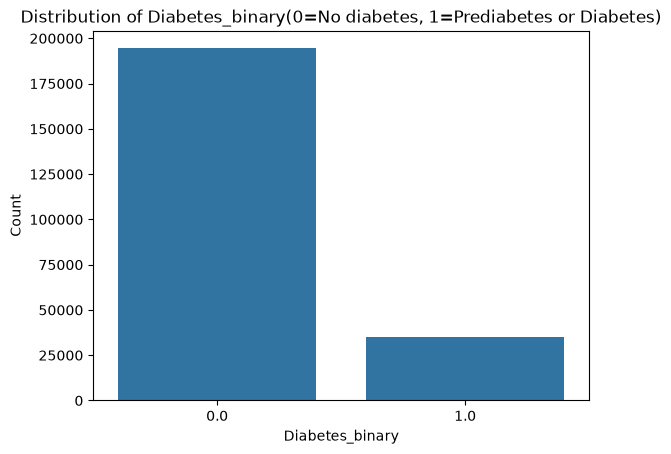

In [13]:
# Visualise the distribution of the target variable (adapted from Tutorial 5, Iqbal, 2026)
sns.countplot(x="Diabetes_binary",data = df)
plt.title("Distribution of Diabetes_binary(0=No diabetes, 1=Prediabetes or Diabetes)")
plt.xlabel("Diabetes_binary")
plt.ylabel("Count")
plt.show()

This first graph shows that most people in the dataset do not have diabetes: around 194,000 people are in class 0 and around 30,000 in class 1, which means that there are approximately 5 times more people without diabetes than with prediabetes or diabetes.
This is important because the classes are imbalanced, which I have to take into account when building the models. For this reason, stratified splits will be used, and I will pay special attention to how well the models identify people in class 1 (recall and F1-score), not just to the overall accuracy.

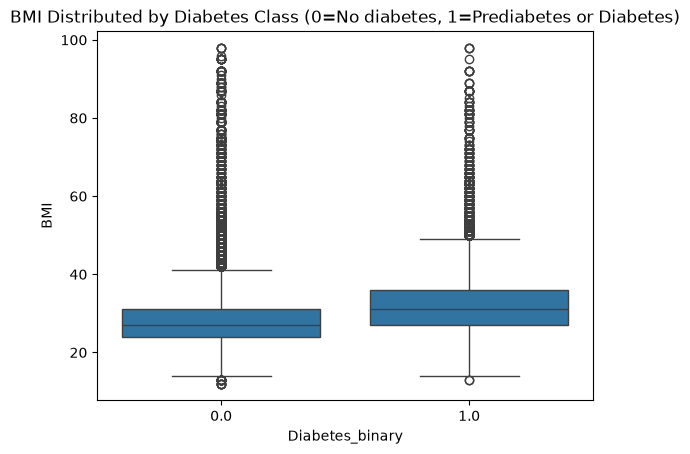

In [14]:
# Boxplot (adapted from Data Preparation module, CCT College Dublin)
sns.boxplot(x="Diabetes_binary", y="BMI", data=df)
plt.title("BMI Distributed by Diabetes Class (0=No diabetes, 1=Prediabetes or Diabetes)")
plt.xlabel("Diabetes_binary")
plt.ylabel("BMI")
plt.show()

This boxplot help me to shows that people with or prediabetes usually have a higher BMI than people without diabetes, class 1 had a median of about 31 in BMI in contrast with class 0 that have about 27.
I also noticed that there are several outliers in both groups, especially at higher BMIs values so I decided to keep them because they could represent real individuals with high BMI and this information is important for predicting diabetes. Additionally, models like Random Forest won't be affected by outliers, as they split the data using thresholds rather than distances(Iqbal, 2026a)while scaling will be applied for distance-based models such as SVM (Iqbal,2026b).

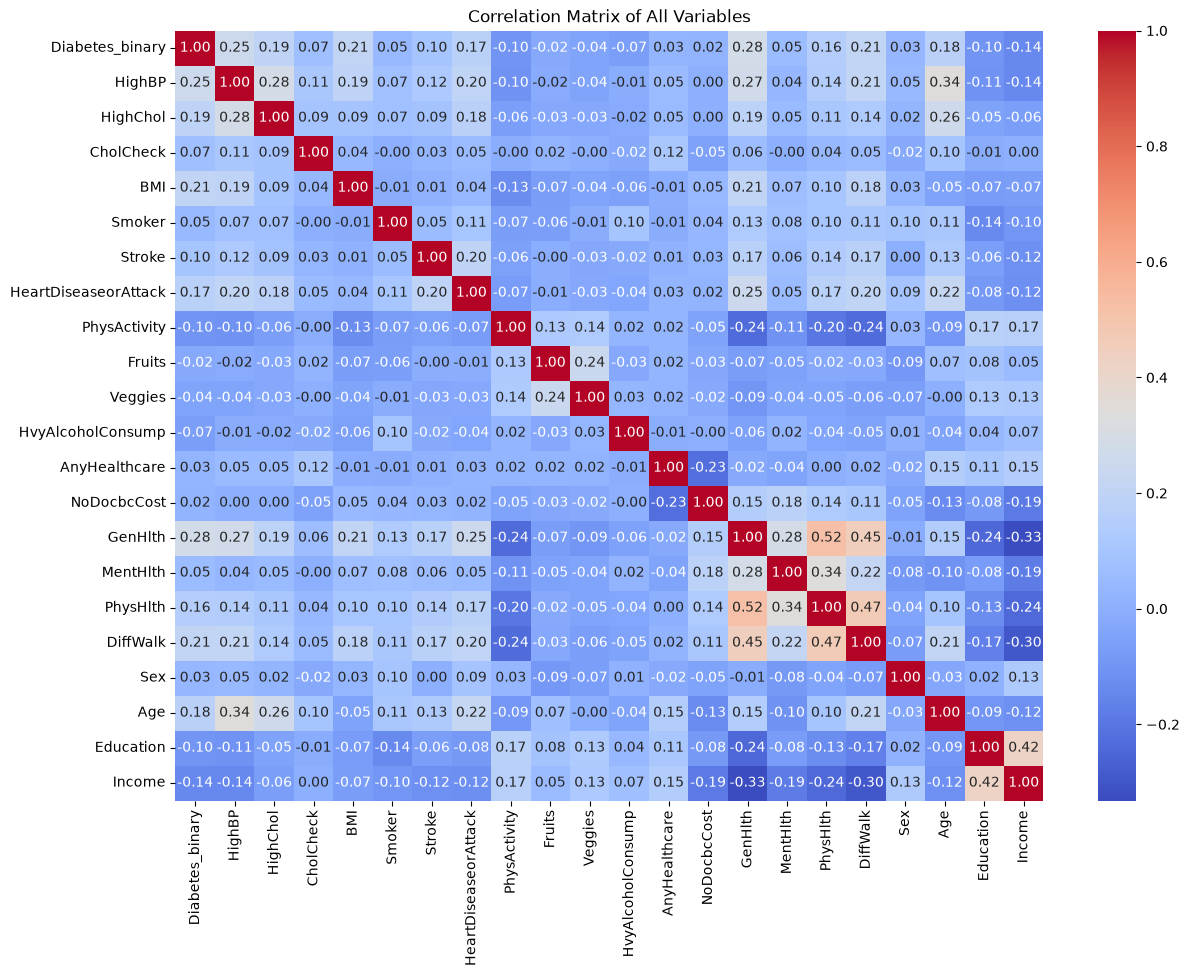

In [15]:
# Correlation heatmap (adapted from Data Preparation module, CCT College Dublin; heatmap also used in Tutorial 5, Iqbal, 2026)
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of All Variables")
plt.show()

Observation:
- In the Diabetes relationship the General Health (GenHlth, 0.28), High Blood Pressure (HighBP, 0.25), and BMI (0.21) show the strongest correlations with Diabetes_binary. However, all correlations are relatively weak, which means that no single variable can predict diabetes on its own.
- Lifestyle and clinical factors: The clinical factors show stronger correlation with diabetes than lifestyle variables such as smoking(Smoker), alcohol(HvyAlcoholConsum), fruit(Fruits) and vegetable(Veggies) consumption.
- Some other variables are also related to each other, for example, General Health (GenHlth) is related to Physical Health (PhysHlth) and Education is related with Income, but these relationships are not strong enough to remove any variables at this stage.

## Data Preparation for Machine Learning Model

Due to the large size of the dataset (229,474 records), I have to take a stratified random sample of 10,000 records to save time during the model training and make the analysis more manageable, by applying stratified sampling will maintain the same proportion of individuals with or without prediabetes/diabetes as in the original dataset.

In [16]:
# Stratified sample of 10,000 records (train_test_split adapted from Tutorial 1, Iqbal, 2026)
from sklearn.model_selection import train_test_split     #Tutorial 1
df_sample,_=train_test_split(df,train_size=10000,
                             stratify=df["Diabetes_binary"],
                             random_state=38)

In [17]:
df_sample.shape

(10000, 22)

In [18]:
df_sample["Diabetes_binary"].value_counts()

Diabetes_binary
0.0    8471
1.0    1529
Name: count, dtype: int64

After applied Stratified the size still includes around 1,500 records from class 1 (Prediabetes/Diabetes) which will be enough for training and testing the models.

In [19]:
# Separate predictor variables (X) and target variable (y) (adapted from Tutorial 1, Iqbal,2026)
X = df_sample.drop(["Diabetes_binary"], axis = 1)  #keep the predictor variables
y= df_sample["Diabetes_binary"]       #Target variable
print (X.shape, y.shape)

(10000, 21) (10000,)


# Modelling

# Model 1 - Random Forest
- What is it? Random Forest is a machine learning model that combines many decision trees, whose predictions are combined by majority vote (Breiman, 2001; Iqbal,2026a)
- Why did I choose it? It is used because it can capture complex relationships among variables,  doesn't require scaling of the variables and can handle the outliers, so, Random Forest can measure the importance of each variable which is going to help me to identify which health indicators are more important for diabetes prediction.
- Limitation: The drawback is the difficulty to interpret because it involves a large number of decision trees and it requires more computing time.

## Random Forest - Test size 5%

In [20]:
# Split the sample into training (95%) and test (5%) sets (adapted from Tutorial 1, Iqbal, 2026)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, 
                                                    stratify = y, random_state = 38)

#Display the rows and columns (dimensions after splitting)
print ("Train:", X_train.shape, y_train.shape)
print ("Test:", X_test.shape, y_test.shape)

Train: (9500, 21) (9500,)
Test: (500, 21) (500,)


In [21]:
# Train a Random Forest (adapted from Random Forest - Practical, Iqbal, 2026)
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 1000, random_state = 38)
#Train the model using the training set
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [22]:
# Import scikit-learn metrics module for accuracy calculation (adapted from Random Forest-Practical, Iqbal, 2026)
from sklearn import metrics
print("Train accuracy:{:.2f}".format(clf_RF.score(X_train, y_train)))    #Rounded up to 2 decimal
print("Test accuracy:{:.2f}".format(metrics.accuracy_score(y_test, y_pred)))
print(metrics.classification_report(y_test, y_pred))

Train accuracy:1.00
Test accuracy:0.84
              precision    recall  f1-score   support

         0.0       0.87      0.96      0.91       424
         1.0       0.46      0.17      0.25        76

    accuracy                           0.84       500
   macro avg       0.67      0.57      0.58       500
weighted avg       0.81      0.84      0.81       500



On the training data, the model achieved a perfect score of 100%, but only 84% on the test data, suggesting overfitting.

Although the model’s test accuracy is 84%, this may be misleading because the dataset consists mostly of people without diabetes. A model that always predicted “no diabetes” would achieve a similar accuracy (84.8%).

The main problem is the low recall for class 1, which is only 17%. This means that the model detects only a small number of people with diabetes or prediabetes and misses many positive cases.

These are the results of a baseline model, which needs to be improved. GridSearch will be used to try to improve the model’s performance, especially for class 1.

## Random Forest - Test size 15%

In [23]:
# Split the sample into training (85%) and test (15%) sets (adapted from Tutorial 1, Iqbal, 2026)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, 
                                                    stratify = y, random_state = 38)

#Display the rows and columns (dimensions after splitting)
print ("Train:", X_train.shape, y_train.shape)
print ("Test:", X_test.shape, y_test.shape)

Train: (8500, 21) (8500,)
Test: (1500, 21) (1500,)


In [24]:
# Train a Random Forest (adapted from Random Forest - Practical, Iqbal, 2026)
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 1000, random_state = 38)
#Train the model using the training set
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [25]:
# Import scikit-learn metrics module for accuracy calculation (adapted from Random Forest-Practical, Iqbal, 2026)
from sklearn import metrics
print("Train accuracy:{:.2f}".format(clf_RF.score(X_train, y_train)))    #Rounded up to 2 decimal
print("Test accuracy:{:.2f}".format(metrics.accuracy_score(y_test, y_pred)))
print(metrics.classification_report(y_test, y_pred))

Train accuracy:1.00
Test accuracy:0.85
              precision    recall  f1-score   support

         0.0       0.86      0.97      0.92      1271
         1.0       0.51      0.16      0.24       229

    accuracy                           0.85      1500
   macro avg       0.69      0.56      0.58      1500
weighted avg       0.81      0.85      0.81      1500



Compared with the 5% split, the model's test accuracy increased slightly from 84% to 85%. However, the recall for class 1 decreased from 17% to 16%, so the model still missed most of the respondents with prediabetes or diabetes
The training accuracy remained at 100%, which still indicates overfitting. Nevertheless, the results are very similar across both splits, suggesting that the model's performance is stable.
Overall, the difference between the splits is small, and I need to improve the detection of class 1.

## Random Forest - Test size 25%

In [26]:
# Split the sample into training (75%) and test (25%) sets (adapted from Tutorial 1, Iqbal, 2026)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, 
                                                    stratify = y, random_state = 38)

#Display the rows and columns (dimensions after splitting)
print ("Train:", X_train.shape, y_train.shape)
print ("Test:", X_test.shape, y_test.shape)

Train: (7500, 21) (7500,)
Test: (2500, 21) (2500,)


In [27]:
# Train a Random Forest (adapted from Random Forest - Practical, Iqbal, 2026)
from sklearn.ensemble import RandomForestClassifier

# Create a Random Forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 1000, random_state = 38)
#Train the model using the training set
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [28]:
# Import scikit-learn metrics module for accuracy calculation (adapted from Random Forest-Practical, Iqbal, 2026)
from sklearn import metrics
print("Train accuracy:{:.2f}".format(clf_RF.score(X_train, y_train)))    #Rounded up to 2 decimal
print("Test accuracy:{:.2f}".format(metrics.accuracy_score(y_test, y_pred)))
print(metrics.classification_report(y_test, y_pred))

Train accuracy:1.00
Test accuracy:0.85
              precision    recall  f1-score   support

         0.0       0.87      0.97      0.92      2118
         1.0       0.53      0.16      0.25       382

    accuracy                           0.85      2500
   macro avg       0.70      0.57      0.58      2500
weighted avg       0.81      0.85      0.81      2500



After testing different train/test splits (5%, 15% and 25% test sizes), I noticed that the results were very similar. The test accuracy was always between 84% and 85%, while the recall for class 1 was between 16% and 17%. This shows that changing the test size didn't significantly affect the model's performance, suggesting that the model is stable.
The model still showed 100% training accuracy in all three experiments, which indicates overfitting.
At the moment, the model detects only a small proportion of people with prediabetes or diabetes which is around 16%-17%, that is so a further improvement is needed.

## Random Forest - Cross validation

In [29]:
# Cross-validation for each test size (adapted from Tutorials 2 and 4, Iqbal, 2026)
from sklearn.model_selection import cross_val_score

test_sizes = [0.05, 0.15, 0.25]

for size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size,
                                                        stratify = y, random_state = 38)

    # Perform 5-fold cross-validation on the training set (adapted from Tutorial 4, Iqbal, 2026)
    cv_accuracy = cross_val_score(clf_RF, X_train, y_train, cv = 5, scoring = "accuracy")
    cv_recall = cross_val_score(clf_RF, X_train, y_train, cv = 5, scoring = "recall")

    # Average scores and standard deviation to measure stability across folds
    # (standard deviation adapted from Statistical Techniques for Data Analytics notebooks, CCT College Dublin, 2026)
    print(f"Test size: {size}")
    print(f"Mean CV accuracy: {np.mean(cv_accuracy):.2f}")
    print(f"Mean CV recall (class 1): {np.mean(cv_recall):.2f}")
    print(f"Standard deviation of CV accuracy: {np.std(cv_accuracy):.2f}")
    print(f"Standard deviation of CV recall: {np.std(cv_recall):.2f}")

Test size: 0.05
Mean CV accuracy: 0.85
Mean CV recall (class 1): 0.15
Standard deviation of CV accuracy: 0.00
Standard deviation of CV recall: 0.02
Test size: 0.15
Mean CV accuracy: 0.85
Mean CV recall (class 1): 0.13
Standard deviation of CV accuracy: 0.00
Standard deviation of CV recall: 0.03
Test size: 0.25
Mean CV accuracy: 0.85
Mean CV recall (class 1): 0.13
Standard deviation of CV accuracy: 0.01
Standard deviation of CV recall: 0.01


After applying 5-fold cross-validation to evaluate the Random Forest model with three different test sizes (5%, 15% and 25%), the results are the following:
- The mean accuracy was 85% in all three experiments, while the mean recall for class 1 was low, ranging from 13% to 15%.
- The standard deviations were also very small (0.00–0.03), which indicates that the model produced consistent results across the different folds.
- Overall, the model is stable, but it still struggles to identify prediabetes or diabetes cases. Therefore, Grid Search will be used to try to improve the model’s performance, especially for class 1.

# Model 2 - Support Vector Machine (SVM)
- What is it? SVM is a machine learning model that determines the best boundary for separating different groups of data with the largest possible margin (Cortes and Vapnik, 1995; Iqbal, 2026d).
- Why did I choose it? I selected SVM since it operates differently from Random Forest and is able to recognise complex patterns by using various kernels. Also it is helpful for comparing different methods for diabetes prediction. I'm also able to use GridSearch to select the best model settings (Iqbal, 2026b)
- Limitation: SVM requires feature scaling and may be slow when it handles large datasets. It is also harder to interpret and it is sensitive to ouliers.

## SVM test size - 5%

In [30]:
# Split the sample into training (95%) and test (5%) sets (adapted from Tutorial 1, Iqbal, 2026)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, 
                                                    stratify = y, random_state = 38)

In [31]:
# Scale the features (adapted from Tutorial 5, Iqbal, 2026)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
# Train an SVM classifier (adapted from Tutorial 5, Iqbal, 2026)
from sklearn.svm import SVC
clf_SVM = SVC(kernel = "rbf")

# Using the scaled training set
clf_SVM.fit(X_train_scaled, y_train)

# Predict the classes of the scaled test set
y_pred = clf_SVM.predict(X_test_scaled)

In [33]:
# Evaluate the model (adapted from Random Forest - Practical, Iqbal, 2026)
print("Train accuracy:{:.2f}".format(clf_SVM.score(X_train_scaled, y_train)))    #Rounded up to 2 decimal
print("Test accuracy:{:.2f}".format(metrics.accuracy_score(y_test, y_pred)))
print(metrics.classification_report(y_test, y_pred))

Train accuracy:0.86
Test accuracy:0.84
              precision    recall  f1-score   support

         0.0       0.85      0.98      0.91       424
         1.0       0.20      0.03      0.05        76

    accuracy                           0.84       500
   macro avg       0.52      0.50      0.48       500
weighted avg       0.75      0.84      0.78       500



The SVM achieved 86% accuracy on the training set and 84% on the test set, it shows no overfitting.
However, the main problem is that the recall for class 1 is only 3% which means that the model detects very few people with prediabetes or diabetes and misses almost all the positive cases, in contrast with Random Forest which achieved 17% recall for class 1, so the SVM perfomrs worse on the positive cases. I will try to improve them especially class 1 by using GridSearch.

## SVM test size - 15%

In [42]:
# Split the sample into training (85%) and test (15%) sets (adapted from Tutorial 1, Iqbal, 2026)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, 
                                                    stratify = y, random_state = 38)

In [35]:
# Scale the features (adapted from Tutorial 5, Iqbal, 2026)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [36]:
# Train an SVM classifier (adapted from Tutorial 5, Iqbal, 2026)
from sklearn.svm import SVC
clf_SVM = SVC(kernel = "rbf")

# Using the scaled training set
clf_SVM.fit(X_train_scaled, y_train)

# Predict the classes of the scaled test set
y_pred = clf_SVM.predict(X_test_scaled)

In [37]:
# Evaluate the model (adapted from Random Forest - Practical, Iqbal, 2026)
print("Train accuracy:{:.2f}".format(clf_SVM.score(X_train_scaled, y_train)))    #Rounded up to 2 decimal
print("Test accuracy:{:.2f}".format(metrics.accuracy_score(y_test, y_pred)))
print(metrics.classification_report(y_test, y_pred))

Train accuracy:0.86
Test accuracy:0.85
              precision    recall  f1-score   support

         0.0       0.85      0.99      0.92      1271
         1.0       0.55      0.05      0.09       229

    accuracy                           0.85      1500
   macro avg       0.70      0.52      0.50      1500
weighted avg       0.81      0.85      0.79      1500



Compared with the 5% split, the model's training accuracy remained at 86%, and it is not showing signs of overfitting. In the case with test accuracy, increased slightly from 84% to 85%. 
However, the recall for class 1 only increased from 3% to 5% which means that the model still identifies very few of the respondents with prediabetes or diabetes.
Compared with Random Forest, SVM still performs poorly at identifying positive cases.

## SVM test size - 25%

In [38]:
# Split the sample into training (75%) and test (25%) sets (adapted from Tutorial 1, Iqbal, 2026)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, 
                                                    stratify = y, random_state = 38)

In [39]:
# Scale the features (adapted from Tutorial 5, Iqbal, 2026)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
# Train an SVM classifier (adapted from Tutorial 5, Iqbal, 2026)
from sklearn.svm import SVC
clf_SVM = SVC(kernel = "rbf")

# Using the scaled training set
clf_SVM.fit(X_train_scaled, y_train)

# Predict the classes of the scaled test set
y_pred = clf_SVM.predict(X_test_scaled)

In [41]:
# Evaluate the model (adapted from Random Forest - Practical, Iqbal, 2026)
print("Train accuracy:{:.2f}".format(clf_SVM.score(X_train_scaled, y_train)))    #Rounded up to 2 decimal
print("Test accuracy:{:.2f}".format(metrics.accuracy_score(y_test, y_pred)))
print(metrics.classification_report(y_test, y_pred))

Train accuracy:0.86
Test accuracy:0.85
              precision    recall  f1-score   support

         0.0       0.85      0.99      0.92      2118
         1.0       0.50      0.05      0.09       382

    accuracy                           0.85      2500
   macro avg       0.68      0.52      0.50      2500
weighted avg       0.80      0.85      0.79      2500



After testing different train/test splits (5%, 15% and 25% test sizes), I noticed that the results were very similar. The training accuracy remained stable at 86% while the test accuracy was between 84% and 85%, which indicates the model is stable and that there was no sign of overfitting.
However, the recall for class 1 remained low, between 3% and 5%, which means that the model identified only a small number of cases of prediabetes or diabetes, so compared to Random Forest, SVM performs less well in detecting positive cases.

## SVM - Cross validation

In [45]:
# Cross-validation for each test size (adapted from Tutorials 2 and 4, Iqbal, 2026)
from sklearn.model_selection import cross_val_score

test_sizes = [0.05, 0.15, 0.25]

for size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = size,
                                                        stratify = y, random_state = 38)
    # Scale the features (adapted from Tutorial 5, Iqbal, 2026)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # Perform 5-fold cross-validation on the scaled set (adapted from Tutorial 4, Iqbal, 2026)
    cv_accuracy = cross_val_score(clf_SVM, X_train_scaled, y_train, cv = 5, scoring = "accuracy")
    cv_recall = cross_val_score(clf_SVM, X_train_scaled, y_train, cv = 5, scoring = "recall")

    # Average scores and standard deviation to measure stability across folds
    # (standard deviation adapted from Statistical Techniques for Data Analytics notebooks, CCT College Dublin, 2026)
    print(f"Test size: {size}")
    print(f"Mean CV accuracy: {np.mean(cv_accuracy):.2f}")
    print(f"Mean CV recall (class 1): {np.mean(cv_recall):.2f}")
    print(f"Standard deviation of CV accuracy: {np.std(cv_accuracy):.2f}")
    print(f"Standard deviation of CV recall: {np.std(cv_recall):.2f}")

Test size: 0.05
Mean CV accuracy: 0.85
Mean CV recall (class 1): 0.05
Standard deviation of CV accuracy: 0.00
Standard deviation of CV recall: 0.01
Test size: 0.15
Mean CV accuracy: 0.85
Mean CV recall (class 1): 0.05
Standard deviation of CV accuracy: 0.00
Standard deviation of CV recall: 0.01
Test size: 0.25
Mean CV accuracy: 0.85
Mean CV recall (class 1): 0.05
Standard deviation of CV accuracy: 0.00
Standard deviation of CV recall: 0.01


I used 5-fold cross-validation to evaluate the SVM model with three different test sizes (5%, 15% and 25%), the results are the following:
- The mean accuracy was stable at 85% across all experiments, while the mean recall for class 1 was only 5%, showing that the model identifies very few people diabetes or prediabetes.

- The standard deviation was very low (0.00-0.01), meaning that the model produced consistent results across the different folds.

- Compared with Random Forest, SVM has a lower recall for class 1, even though both models achieved similar accuracy.

- Overall the performance between both models, Random Forest was better at identifying the positive cases. This shows that accuracy alone is not sufficient to evaluate the models. As a next step, I will optimise the performance of both models using GridSearch.

## Hyperparameter 

GridSearch - I will apply Grid Search, which tests all combinations of the specified parameter values, using cross-validation, to find the settings that give the best model performance.
- I chose the 25% test split because it gives me a larger test set of 2,500 records so I can evaluate the model and compare its performance more reliably.

## GridSearch - SVM 25%

In [46]:
# GridSearchCV to find the SVM parameters (adapted from Tutorial 5, Iqbal, 2026)
from sklearn.model_selection import GridSearchCV

# Define parameter grid
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [1, 0.1, 0.01, 0.001],
    "kernel": ["rbf"]
}

# Perform grid search with 5-fold cross-validation
grid = GridSearchCV(SVC(), param_grid, cv = 5, verbose = 1)
grid.fit(X_train_scaled, y_train)

# Best parameters and best cross-validation
print("Best Parameters:", grid.best_params_)
print("Best Estimator:", grid.best_estimator_)
print("Best CV accuracy: {:.2f}".format(grid.best_score_))

# Make predictions
grid_predictions = grid.predict(X_test_scaled)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Best Estimator: SVC(C=1, gamma=0.1)
Best CV accuracy: 0.85


In [48]:
# Evaluate the tuned SVM model (adapted from Random Forest - Practical and Tutorial 5, Iqbal, 2026)
print("Test accuracy: {:.2f}".format(metrics.accuracy_score(y_test, grid_predictions)))
print(metrics.classification_report(y_test, grid_predictions))

Test accuracy: 0.84
              precision    recall  f1-score   support

         0.0       0.85      0.98      0.91      2118
         1.0       0.43      0.07      0.11       382

    accuracy                           0.84      2500
   macro avg       0.64      0.52      0.51      2500
weighted avg       0.79      0.84      0.79      2500



Observation:
- The GridSearchCV evaluated 16 combinations of parameters using 5-fold cross-validation demostrate that the optimal parameters found were: C = 1, gamma = 0.1 and kernel = rbf, with a mean, with a mean CV accuracy of 85%.
- The tuned model reached 84% accuracy on the test set, while the baseline model had 85%.
- Recall for class 1 increased slightly, from 5% to 7%, and the F1-score increased from 0.09 to 0.11. The model now identifies a few more respondents with prediabetes or diabetes, though recall remains low.
- This small improvement happened because GridSearch focused on accuracy, which favours the majority class.
- By using recall as the optimisation metric might help improve class 1 detection.

## Confusion matrix - SVM

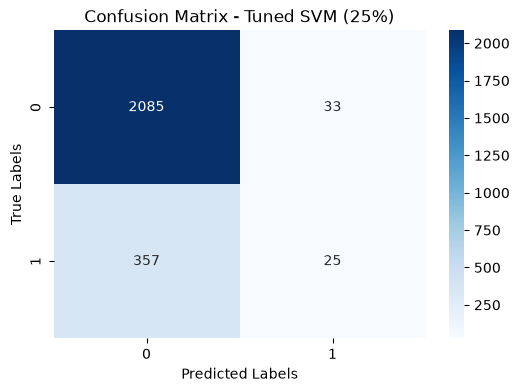

In [50]:
# Confusion matrix of the tuned SVM (adapted from Tutorial 5, Iqbal, 2026)
from sklearn.metrics import confusion_matrix

cmG = confusion_matrix(y_test, grid_predictions)

plt.figure(figsize = (6, 4))
sns.heatmap(cmG, annot = True, fmt = "d", cmap = "Blues")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix - Tuned SVM (25%)")
plt.show()

Observations:
- The confusion matrix shows how well the tuned SVM model classified people with and without diabetes.
- The model it had only detected 25 of the 382 positive cases and missed 357 people who actually have prediabetes or diabetes.  Also, it identified 2,085 of the 2,118 people without diabetes.
- I can confirm that the model struggles to identify people in class 1 and tends to classify most people as not having diabetes.
- This is an important limitation, because if positive cases are missed, people at risk may be ovelooked. Hence, the detection of class 1 remains a priority.

## GridSearchCV - Random Forest 25%

In [52]:
# GrindSearchCV for Random Forest (structure adapted from Tutorial 5, Iqbal, 2026)
# n_estimators from Random Forest - Practical; max_depth from Tutorial 3, Iqbal, 2026)

# Define parameter grid
param_grid_rf = {
    "n_estimators": [100, 300],
    "max_depth": [5, 10, None]
}

# Perform grid search with 5-fold cross-validation (Random Forest does not need scaled data)
grid_rf = GridSearchCV(RandomForestClassifier(random_state = 38), param_grid_rf, cv = 5, verbose = 1)
grid_rf.fit(X_train, y_train)

# Best parameters estimator and cross-validation accuracy
print("Best Parameters:", grid_rf.best_params_)
print("Best Estimator:", grid_rf.best_estimator_)
print("Best CV accuracy: {:.2f}".format(grid_rf.best_score_))

# Make predictions
grid_rf_predictions = grid_rf.predict(X_test)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'max_depth': 10, 'n_estimators': 300}
Best Estimator: RandomForestClassifier(max_depth=10, n_estimators=300, random_state=38)
Best CV accuracy: 0.85


In [54]:
# Evaluate the tuned Random Forest model (adapted from Random Forest - Practical, Iqbal, 2026)
print("Train accuracy: {:.2f}".format(grid_rf.score(X_train, y_train)))
print("Test accuracy: {:.2f}".format(metrics.accuracy_score(y_test, grid_rf_predictions)))
print(metrics.classification_report(y_test, grid_rf_predictions))

Train accuracy: 0.90
Test accuracy: 0.85
              precision    recall  f1-score   support

         0.0       0.86      0.98      0.92      2118
         1.0       0.57      0.12      0.20       382

    accuracy                           0.85      2500
   macro avg       0.71      0.55      0.56      2500
weighted avg       0.82      0.85      0.81      2500



## Confusion Matrix - Random Forest

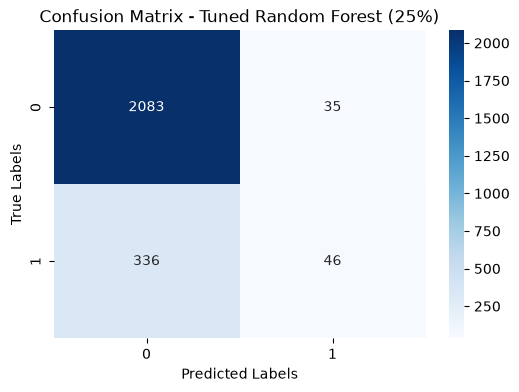

In [56]:
# Confusion matrix of the tuned Random Forest (adapted from Tutorial 5, Iqbal, 2026)
cm_rf = confusion_matrix(y_test, grid_rf_predictions)

plt.figure(figsize = (6,4))
sns.heatmap(cm_rf, annot =True, fmt = "d", cmap = "Blues")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix - Tuned Random Forest (25%)")
plt.show()

Observations:
- The confusion matrix shows that Random Forest correctly identified 46 of the 382 people with prediabetes or diabetes, while 336 positive cases were missed.
- Random Forest found almost twice as many positive cases compared with the SVM (25), with a similar number of false positives (35 compared with 33).
- However, both models still missed most positive cases.
- For the detection of diabetes, Random Forest performed better than SVM, but further improvements are needed